In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Blacksheep Labs: Spam Detection Project Ready!")

Blacksheep Labs: Spam Detection Project Ready!


In [7]:
# Blacksheep Labs - Spam Email Dataset

data = {
    "email_length": [50, 200, 75, 300, 100, 250, 60, 400, 120, 350],
    "num_links": [0, 3, 0, 5, 1, 4, 0, 6, 1, 5],
    "spam": [0, 1, 0, 1, 0, 1, 0, 1, 0, 1]
}

df = pd.DataFrame(data)

print("Blacksheep Labs: Email Dataset Loaded!")
display(df)

Blacksheep Labs: Email Dataset Loaded!


,email_length,num_links,spam
0,50,0,0
1,200,3,1
2,75,0,0
3,300,5,1
4,100,1,0
5,250,4,1
6,60,0,0
7,400,6,1
8,120,1,0
9,350,5,1


In [8]:
# Check the first 5 rows
print("First 5 Emails:")
display(df.head())

# Check dataset dimensions
print("\nDataset Shape:")
print(df.shape)

# Check for missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Count spam and non-spam emails
print("\nSpam Distribution:")
print(df["spam"].value_counts())

First 5 Emails:


,email_length,num_links,spam
0,50,0,0
1,200,3,1
2,75,0,0
3,300,5,1
4,100,1,0



Dataset Shape:
(10, 3)

Missing Values:
email_length    0
num_links       0
spam            0
dtype: int64

Spam Distribution:
spam
0    5
1    5
Name: count, dtype: int64


In [9]:
# Blacksheep Labs - Summary Statistics

print("Email Dataset Summary Statistics:")

display(df.describe())

Email Dataset Summary Statistics:


,email_length,num_links,spam
count,10.000000,10.000000,10.000000
mean,190.500000,2.500000,0.500000
std,128.332251,2.368778,0.527046
min,50.000000,0.000000,0.000000
25%,81.250000,0.250000,0.000000
50%,160.000000,2.000000,0.500000
75%,287.500000,4.750000,1.000000
max,400.000000,6.000000,1.000000


In [10]:
# Blacksheep Labs - Compare Email Categories

spam_summary = df.groupby("spam")[["email_length", "num_links"]].mean()

print("Average Email Characteristics by Category:")
display(spam_summary)

Average Email Characteristics by Category:


,email_length,num_links
spam,,
0,81.0,0.4
1,300.0,4.6


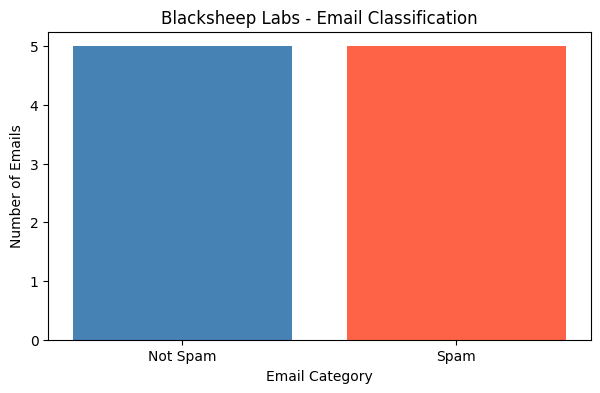

In [11]:
# Blacksheep Labs - Spam Distribution

spam_counts = df["spam"].value_counts().sort_index()

plt.figure(figsize=(7, 4))

plt.bar(
    ["Not Spam", "Spam"],
    spam_counts.values,
    color=["steelblue", "tomato"]
)

plt.title("Blacksheep Labs - Email Classification")
plt.xlabel("Email Category")
plt.ylabel("Number of Emails")

plt.show()

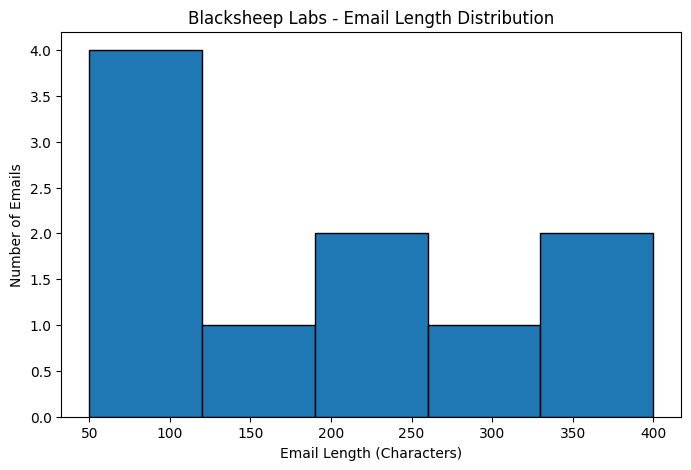

In [12]:
# Blacksheep Labs - Email Length Histogram

plt.figure(figsize=(8, 5))

plt.hist(
    df["email_length"],
    bins=5,
    edgecolor="black"
)

plt.title("Blacksheep Labs - Email Length Distribution")
plt.xlabel("Email Length (Characters)")
plt.ylabel("Number of Emails")

plt.show()

In [13]:
# Blacksheep Labs - Outlier Detection

Q1 = df["email_length"].quantile(0.25)
Q3 = df["email_length"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df["email_length"] < lower_bound) |
    (df["email_length"] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

print("\nPotential Outliers:")
display(outliers)

Q1: 81.25
Q3: 287.5
IQR: 206.25
Lower Bound: -228.125
Upper Bound: 596.875

Potential Outliers:


,email_length,num_links,spam


In [14]:
# Blacksheep Labs - Detect an Extreme Outlier

# Create a copy of our original dataset
df_outlier = df.copy()

# Add one unusually long email
df_outlier.loc[len(df_outlier)] = [5000, 8, 1]

# Calculate the IQR again
Q1 = df_outlier["email_length"].quantile(0.25)
Q3 = df_outlier["email_length"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Find potential outliers
outliers = df_outlier[
    (df_outlier["email_length"] < lower_bound) |
    (df_outlier["email_length"] > upper_bound)
]

print("Potential Outliers:")
display(outliers)

Potential Outliers:


,email_length,num_links,spam
10,5000,8,1


In [15]:
# Blacksheep Labs - Correlation Matrix

correlation_matrix = df.corr(numeric_only=True)

print("Blacksheep Labs - Correlation Matrix:")
display(correlation_matrix)

Blacksheep Labs - Correlation Matrix:


,email_length,num_links,spam
email_length,1.000000,0.989614,0.899409
num_links,0.989614,1.000000,0.934488
spam,0.899409,0.934488,1.000000


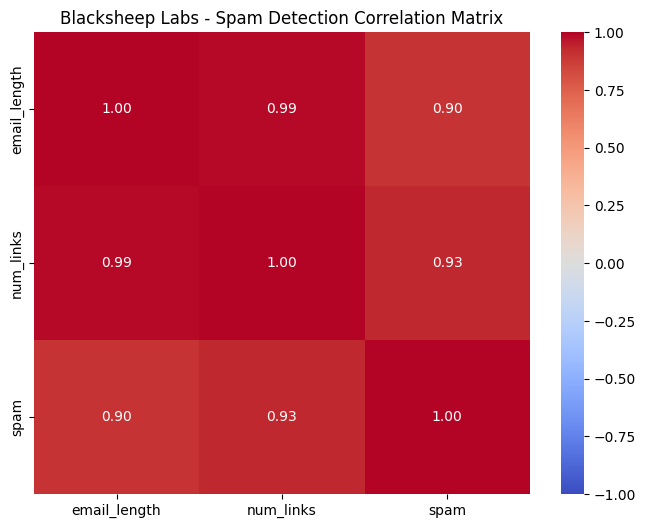

In [16]:
# Blacksheep Labs - Correlation Heatmap

import seaborn as sns

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("Blacksheep Labs - Spam Detection Correlation Matrix")

plt.show()

In [17]:
# Blacksheep Labs - Feature Correlations

spam_correlations = (
    correlation_matrix["spam"]
    .drop("spam")
    .sort_values(key=abs, ascending=False)
)

print("Features Most Correlated with Spam:")
print(spam_correlations)

print("\nStrongest Correlated Feature:")
print(spam_correlations.index[0])

Features Most Correlated with Spam:
num_links       0.934488
email_length    0.899409
Name: spam, dtype: float64

Strongest Correlated Feature:
num_links


In [18]:
# Blacksheep Labs - Logistic Regression Preparation

# Features: information used for predictions
X = df[["email_length", "num_links"]]

# Target: what we want to predict
y = df["spam"]

print("Features (X):")
display(X.head())

print("\nTarget (y):")
display(y.head())

print("\nFeature Shape:", X.shape)
print("Target Shape:", y.shape)

Features (X):


,email_length,num_links
0,50,0
1,200,3
2,75,0
3,300,5
4,100,1



Target (y):


,spam
0,0
1,1
2,0
3,1
4,0



Feature Shape: (10, 2)
Target Shape: (10,)


In [19]:
# Blacksheep Labs - Train/Test Split

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Labels:", y_train.shape)
print("Testing Labels:", y_test.shape)

Training Features: (8, 2)
Testing Features: (2, 2)
Training Labels: (8,)
Testing Labels: (2,)


In [20]:
# Blacksheep Labs - Verify Model Data

print("Training Data:")
print("Features:", X_train.shape)
print("Labels:", y_train.shape)

print("\nTesting Data:")
print("Features:", X_test.shape)
print("Labels:", y_test.shape)

print("\nTraining Class Distribution:")
print(y_train.value_counts())

print("\nTesting Class Distribution:")
print(y_test.value_counts())

print("\nMissing Training Values:")
print(X_train.isnull().sum())

print("\nMissing Testing Values:")
print(X_test.isnull().sum())

Training Data:
Features: (8, 2)
Labels: (8,)

Testing Data:
Features: (2, 2)
Labels: (2,)

Training Class Distribution:
spam
1    4
0    4
Name: count, dtype: int64

Testing Class Distribution:
spam
0    1
1    1
Name: count, dtype: int64

Missing Training Values:
email_length    0
num_links       0
dtype: int64

Missing Testing Values:
email_length    0
num_links       0
dtype: int64


In [21]:
# Blacksheep Labs - Coefficient Interpreter

import math

def interpret_coefficient(coefficient):

    odds_ratio = math.exp(coefficient)

    if coefficient > 0:
        direction = "Increases the odds of spam"

    elif coefficient < 0:
        direction = "Decreases the odds of spam"

    else:
        direction = "No change in the odds of spam"

    print(f"Coefficient: {coefficient}")
    print(f"Odds Ratio: {odds_ratio:.2f}")
    print(f"Interpretation: {direction}")

In [22]:
# Blacksheep Labs - Test Coefficient Function

print("Test 1: Positive Coefficient")
interpret_coefficient(0.80)

print("\nTest 2: Negative Coefficient")
interpret_coefficient(-0.50)

print("\nTest 3: Zero Coefficient")
interpret_coefficient(0)

Test 1: Positive Coefficient
Coefficient: 0.8
Odds Ratio: 2.23
Interpretation: Increases the odds of spam

Test 2: Negative Coefficient
Coefficient: -0.5
Odds Ratio: 0.61
Interpretation: Decreases the odds of spam

Test 3: Zero Coefficient
Coefficient: 0
Odds Ratio: 1.00
Interpretation: No change in the odds of spam


In [23]:
# Blacksheep Labs - Advanced Coefficient Interpreter

def interpret_coefficient(feature, coefficient):

    odds_ratio = math.exp(coefficient)
    percent_change = (odds_ratio - 1) * 100

    print(f"Feature: {feature}")
    print(f"Coefficient: {coefficient}")
    print(f"Odds Ratio: {odds_ratio:.2f}")

    if coefficient > 0:
        print(f"Spam odds increase by {percent_change:.2f}%")

    elif coefficient < 0:
        print(f"Spam odds decrease by {abs(percent_change):.2f}%")

    else:
        print("No change in spam odds")


# Test our upgraded function
interpret_coefficient("Number of Links", 0.80)

print()

interpret_coefficient("Email Length", -0.50)

Feature: Number of Links
Coefficient: 0.8
Odds Ratio: 2.23
Spam odds increase by 122.55%

Feature: Email Length
Coefficient: -0.5
Odds Ratio: 0.61
Spam odds decrease by 39.35%


In [24]:
# Blacksheep Labs - Train Logistic Regression

from sklearn.linear_model import LogisticRegression

# Create our machine learning model
model = LogisticRegression()

# Train the model using training data
model.fit(X_train, y_train)

print("Blacksheep Labs Logistic Regression Model Trained!")

Blacksheep Labs Logistic Regression Model Trained!


In [25]:
# Blacksheep Labs - Spam Predictions

# Predict spam using our testing data
y_pred = model.predict(X_test)

print("Actual Spam Labels:")
print(y_test.values)

print("\nPredicted Spam Labels:")
print(y_pred)

Actual Spam Labels:
[0 1]

Predicted Spam Labels:
[0 1]


In [26]:
# Blacksheep Labs - Spam Probabilities

# Get predicted probabilities for spam (class 1)
spam_probabilities = model.predict_proba(X_test)[:, 1]

# Compare actual labels, predictions, and probabilities
results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred,
    "Spam Probability": spam_probabilities
})

print("Blacksheep Labs - Spam Predictions")
display(results.round(3))

Blacksheep Labs - Spam Predictions


,Actual,Predicted,Spam Probability
0,0,0,0.0
1,1,1,1.0


In [27]:
# Blacksheep Labs - Confusion Matrix

from sklearn.metrics import confusion_matrix

# Compare actual answers with predictions
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
)

print("Blacksheep Labs - Confusion Matrix")
print(cm)

Blacksheep Labs - Confusion Matrix
[[1 0]
 [0 1]]


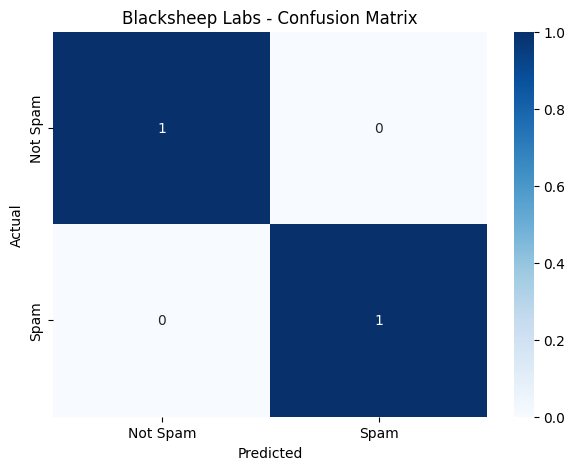

In [28]:
# Blacksheep Labs - Confusion Matrix Heatmap

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Spam", "Spam"],
    yticklabels=["Not Spam", "Spam"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Blacksheep Labs - Confusion Matrix")

plt.show()

In [29]:
# Blacksheep Labs - Classification Report

from sklearn.metrics import classification_report

report = classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Not Spam", "Spam"],
    zero_division=0
)

print("Blacksheep Labs - Classification Report")
print(report)

Blacksheep Labs - Classification Report
              precision    recall  f1-score   support

    Not Spam       1.00      1.00      1.00         1
        Spam       1.00      1.00      1.00         1

    accuracy                           1.00         2
   macro avg       1.00      1.00      1.00         2
weighted avg       1.00      1.00      1.00         2



In [30]:
# Blacksheep Labs - Model Assessment Function

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

def assess_model(y_true, y_pred):

    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, zero_division=0)
    recall = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)

    print("Blacksheep Labs - Model Assessment")
    print(f"Accuracy: {accuracy:.2%}")
    print(f"Precision: {precision:.2%}")
    print(f"Recall: {recall:.2%}")
    print(f"F1-score: {f1:.2%}")

In [31]:
# Blacksheep Labs - Evaluate Our Model

assess_model(y_test, y_pred)

Blacksheep Labs - Model Assessment
Accuracy: 100.00%
Precision: 100.00%
Recall: 100.00%
F1-score: 100.00%


In [32]:
# Blacksheep Labs - Model Performance Summary

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("BLACKSHEEP LABS - MODEL PERFORMANCE")
print("----------------------------------")

print(f"Accuracy: {accuracy:.2%}")
print(f"Precision: {precision:.2%}")
print(f"Recall: {recall:.2%}")
print(f"F1-score: {f1:.2%}")

print("\nMODEL INTERPRETATION")

if precision > recall:
    print("The model performs better at avoiding false spam alarms than at catching all spam.")

elif recall > precision:
    print("The model performs better at catching spam than at avoiding false spam alarms.")

else:
    print("Precision and recall are equal.")

print("\nReminder: Only 2 test emails were evaluated.")

BLACKSHEEP LABS - MODEL PERFORMANCE
----------------------------------
Accuracy: 100.00%
Precision: 100.00%
Recall: 100.00%
F1-score: 100.00%

MODEL INTERPRETATION
Precision and recall are equal.

Reminder: Only 2 test emails were evaluated.
